# Monte Carlo Pricing of a European Call: Making the Estimate More Precise

**Question.** If we price an option with random simulation, how much more precise can we make the answer *without* using more computing effort?

**The plan, in simple words**

1. Price a European call with plain ("standard") Monte Carlo and compare it with the exact Black-Scholes price.
2. Add an **error bar** (a confidence interval) to every estimate, so we know how much to trust it.
3. Try two variance reduction techniques, **antithetic variates** and a **control variate**, and then use **both together**.
4. Compare all four methods with the **same budget**: 1,000 payoff evaluations each.
5. Repeat everything thousands of times to see, in a histogram, which method is really more precise.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(42)   # random number generator; fixed seed so results can be repeated

In [2]:
# Parameters
S0 = 100          # stock price today
K = 105           # strike price
T = 1             # time to maturity (years)
r = 0.05          # risk-free interest rate
sigma = 0.20      # volatility

M = 1000          # budget: number of payoff evaluations given to EVERY method
N = M // 2        # number of antithetic pairs (each pair costs 2 payoff evaluations)

discount = np.exp(-r * T)   # discount factor
z95 = 1.96                  # used for 95% confidence intervals

## 1. The exact answer (our yardstick)

For this simple option there is a closed formula, Black-Scholes. We use it only to check how good the Monte Carlo estimates are. (Monte Carlo is useful in cases where no such formula exists.)

In [3]:
d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
d2 = d1 - sigma * np.sqrt(T)

black_scholes_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
print("Black-Scholes price:", black_scholes_price)

Black-Scholes price: 8.021352235143176


## 2. The Monte Carlo idea

The call price is the discounted *average* payoff. We cannot compute that average exactly, so we:

1. draw random numbers $Z$ from a standard normal distribution,
2. turn each into a possible stock price at maturity, $S_T = S_0 \exp\big((r-\tfrac{\sigma^2}{2})T + \sigma\sqrt{T}\,Z\big)$,
3. compute the discounted payoff $e^{-rT}\max(S_T-K,0)$ for each one,
4. take the average.

Every estimate has some random error. The **standard error** measures its typical size, $\text{SE} = s/\sqrt{n}$ (where $s$ is the standard deviation of the payoffs and $n$ the number of observations). A **95% confidence interval** is $\text{estimate} \pm 1.96\times\text{SE}$.

Two small helper functions keep the code short.

In [4]:
def terminal_price(Z):
    # Stock price at maturity for the random numbers Z
    return S0 * np.exp((r - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)

def discounted_payoff(Z):
    # Discounted call payoff for the random numbers Z
    return discount * np.maximum(terminal_price(Z) - K, 0)

## 3. Method 1: Standard Monte Carlo

Draw $M = 1000$ random numbers and average their payoffs.

In [5]:
# Generate M standard normal random numbers
Z_standard = rng.standard_normal(M)

# Discounted payoff of each scenario
payoff_standard = discounted_payoff(Z_standard)

# Price estimate, standard error and 95% confidence interval
price_standard = payoff_standard.mean()
se_standard = payoff_standard.std(ddof=1) / np.sqrt(M)

print(f"Standard MC price: {price_standard:.4f}")
print(f"Standard error   : {se_standard:.4f}")
print(f"95% CI           : ({price_standard - z95 * se_standard:.4f}, {price_standard + z95 * se_standard:.4f})")

Standard MC price: 7.4907
Standard error   : 0.4009
95% CI           : (6.7050, 8.2764)


## 4. Method 2: Antithetic variates

**Idea.** For every random number $Z$ we also use its mirror image $-Z$. If $Z$ gives a "high stock price" scenario, $-Z$ gives a "low stock price" scenario. The call payoff goes up when $Z$ goes up, so the two payoffs tend to move in opposite directions, and **averaging each pair cancels part of the noise**.

**Same budget.** We use only $N = 500$ random numbers, but each one gives two payoffs, so we still have 1000 payoff evaluations.

In [6]:
# Generate N random numbers and their mirror images
Z = rng.standard_normal(N)
Z_mirror = -Z

# Payoff of each scenario and of its mirror image
payoff_up = discounted_payoff(Z)
payoff_down = discounted_payoff(Z_mirror)

# Average each pair: these N values are our observations
pair_payoff = (payoff_up + payoff_down) / 2

price_av = pair_payoff.mean()
se_av = pair_payoff.std(ddof=1) / np.sqrt(N)

print(f"Antithetic price: {price_av:.4f}")
print(f"Standard error  : {se_av:.4f}")
print(f"95% CI          : ({price_av - z95 * se_av:.4f}, {price_av + z95 * se_av:.4f})")

Antithetic price: 8.1879
Standard error  : 0.3413
95% CI          : (7.5189, 8.8569)


## 5. Method 3: Control variate

**Idea.** There is one quantity whose true average we know exactly: the discounted stock price at maturity, $Y = e^{-rT}S_T$. Its true average is simply today's price $S_0$. (This follows from $\mathbb E[e^{aZ}] = e^{a^2/2}$ for a standard normal $Z$.)

In our sample, the average of $Y$ will not be exactly $S_0$. If it came out **too high**, our sample had "too many high stock prices", so the average payoff is probably **too high** as well, and we correct it downwards (and the other way round). The correction is

$$\hat C_{CV} = \overline{\text{payoff}} - \beta\,\big(\overline{Y} - S_0\big), \qquad \beta = \frac{\mathrm{Cov}(\text{payoff},Y)}{\mathrm{Var}(Y)}.$$

$\beta$ is just the slope of the line that predicts the payoff from $Y$. The stronger the link between payoff and $Y$, the better the correction works. For a call option this link is strong.

Here we correct the **same** 1000 random numbers used in Method 1, so any improvement comes only from the correction.

In [7]:
def cv_adjust(payoff, control):
    # Subtract the part of the payoff's noise that is explained by the control.
    # The control has a known true average: S0.
    beta = np.cov(payoff, control)[0, 1] / np.var(control, ddof=1)
    return payoff - beta * (control - S0)

# Control: discounted stock price at maturity (true average = S0)
control_standard = discount * terminal_price(Z_standard)

adjusted_payoff = cv_adjust(payoff_standard, control_standard)

price_cv = adjusted_payoff.mean()
se_cv = adjusted_payoff.std(ddof=1) / np.sqrt(M)

print(f"Average of the control in our sample: {control_standard.mean():.4f}  (true value: {S0})")
print(f"Control variate price: {price_cv:.4f}")
print(f"Standard error       : {se_cv:.4f}")
print(f"95% CI               : ({price_cv - z95 * se_cv:.4f}, {price_cv + z95 * se_cv:.4f})")

Average of the control in our sample: 99.3742  (true value: 100)
Control variate price: 7.8434
Standard error       : 0.1906
95% CI               : (7.4699, 8.2170)


## 6. Method 4: Antithetic variates + control variate

Nothing new: we apply the control-variate correction to the **antithetic pairs**. For each pair we average the two payoffs *and* the two control values, and then correct as before.

In [8]:
# Control for each antithetic pair: average of the discounted stock prices of Z and -Z
control_pair = discount * (terminal_price(Z) + terminal_price(Z_mirror)) / 2

adjusted_pair = cv_adjust(pair_payoff, control_pair)

price_av_cv = adjusted_pair.mean()
se_av_cv = adjusted_pair.std(ddof=1) / np.sqrt(N)

print(f"Antithetic + CV price: {price_av_cv:.4f}")
print(f"Standard error       : {se_av_cv:.4f}")
print(f"95% CI               : ({price_av_cv - z95 * se_av_cv:.4f}, {price_av_cv + z95 * se_av_cv:.4f})")

Antithetic + CV price: 7.9803
Standard error       : 0.0867
95% CI               : (7.8103, 8.1503)


## 7. Single-run summary

**Careful:** the column `|Error vs BS|` comes from *one* random sample, so it is mostly luck. A good method can still get a bigger error in one run. The width of the confidence interval is the fairer comparison here, and the repeated experiments in Section 9 give the real answer.

In [9]:
names = ["Standard MC", "Antithetic", "Control variate", "Antithetic + Control variate"]
prices = [price_standard, price_av, price_cv, price_av_cv]
ses = [se_standard, se_av, se_cv, se_av_cv]

summary = pd.DataFrame({
    "Method": names,
    "Price": prices,
    "Standard error": ses,
    "CI low": [p - z95 * s for p, s in zip(prices, ses)],
    "CI high": [p + z95 * s for p, s in zip(prices, ses)],
    "Payoff evaluations": [M, 2 * N, M, 2 * N],
    "|Error vs BS|": [abs(p - black_scholes_price) for p in prices],
}).set_index("Method")

print("Black-Scholes price:", black_scholes_price)
summary

Black-Scholes price: 8.021352235143176


,Price,Standard error,CI low,CI high,Payoff evaluations,|Error vs BS|
Method,,,,,,
Standard MC,7.490708,0.400864,6.705014,8.276402,1000,0.530644
Antithetic,8.187909,0.341346,7.518870,8.856948,1000,0.166556
Control variate,7.843440,0.190601,7.469862,8.217018,1000,0.177912
Antithetic + Control variate,7.980275,0.086725,7.810294,8.150255,1000,0.041078


## 8. Why do these techniques work? A quick check with numbers

Both techniques rely on a correlation, and we can measure it.

- **Antithetic:** the variance of the estimator gets multiplied by $(1+\rho)$, where $\rho$ is the correlation between the payoff of $Z$ and the payoff of $-Z$. A negative $\rho$ means a reduction.
- **Control variate:** the variance gets multiplied by $(1-\rho^2)$, where $\rho$ is the correlation between the payoff and the control. A $\rho$ close to $1$ means a big reduction.

In [10]:
# A large sample to measure the correlations accurately
Z_big = rng.standard_normal(200_000)

payoff_big = discounted_payoff(Z_big)
payoff_big_mirror = discounted_payoff(-Z_big)
control_big = discount * terminal_price(Z_big)

rho_av = np.corrcoef(payoff_big, payoff_big_mirror)[0, 1]
rho_cv = np.corrcoef(payoff_big, control_big)[0, 1]

print("Antithetic: correlation between payoff(Z) and payoff(-Z) =", round(rho_av, 3))
print("   -> variance should be multiplied by 1 + rho =", round(1 + rho_av, 3),
      "(about", round(-rho_av * 100), "% reduction)")
print()
print("Control variate: correlation between payoff and control =", round(rho_cv, 3))
print("   -> variance should be multiplied by 1 - rho^2 =", round(1 - rho_cv**2, 3),
      "(about", round(rho_cv**2 * 100), "% reduction)")

Antithetic: correlation between payoff(Z) and payoff(-Z) = -0.368
   -> variance should be multiplied by 1 + rho = 0.632 (about 37 % reduction)

Control variate: correlation between payoff and control = 0.891
   -> variance should be multiplied by 1 - rho^2 = 0.206 (about 79 % reduction)


## 9. Repeating the experiment many times

One run is just one random sample. To see which method is really more precise, we repeat the **whole experiment 5,000 times** and look at how much each method's price estimate jumps around. A method with less variance gives estimates that are more tightly grouped around the true price.

The function below does exactly what Sections 3 to 6 did, packed together so we can repeat it. Each method gets the same budget of `n` payoff evaluations.

In [11]:
def mean_and_se(x):
    # Average of the observations and its standard error
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))

def simulate_all(n):
    # One complete experiment: the four methods with a budget of n payoff evaluations.
    # Standard MC and Control variate share the same n random numbers.
    Zs = rng.standard_normal(n)
    pay = discounted_payoff(Zs)
    ctrl = discount * terminal_price(Zs)

    # Antithetic and Antithetic + Control variate share the same n/2 random numbers
    Za = rng.standard_normal(n // 2)
    pair = (discounted_payoff(Za) + discounted_payoff(-Za)) / 2
    ctrl_pair = discount * (terminal_price(Za) + terminal_price(-Za)) / 2

    return {
        "Standard MC": mean_and_se(pay),
        "Antithetic": mean_and_se(pair),
        "Control variate": mean_and_se(cv_adjust(pay, ctrl)),
        "Antithetic + Control variate": mean_and_se(cv_adjust(pair, ctrl_pair)),
    }

In [12]:
R = 5000
all_prices = {name: np.zeros(R) for name in names}
all_ses = {name: np.zeros(R) for name in names}

for i in range(R):
    results = simulate_all(M)
    for name in names:
        all_prices[name][i], all_ses[name][i] = results[name]

In [13]:
variance_standard = all_prices["Standard MC"].var(ddof=1)

rows = []
for name in names:
    p, s = all_prices[name], all_ses[name]
    rows.append({
        "Method": name,
        "Average price": p.mean(),
        "Variance of the estimates": p.var(ddof=1),
        "Variance reduction (%)": (1 - p.var(ddof=1) / variance_standard) * 100,
        "Times smaller variance (x)": variance_standard / p.var(ddof=1),
        "Typical error (RMSE)": np.sqrt(np.mean((p - black_scholes_price) ** 2)),
        "CI contains true price (%)": np.mean(np.abs(p - black_scholes_price) <= z95 * s) * 100,
    })

repeated = pd.DataFrame(rows).set_index("Method")
print("Black-Scholes price:", black_scholes_price, " | experiments:", R, " | budget:", M)
repeated

Black-Scholes price: 8.021352235143176  | experiments: 5000  | budget: 1000


,Average price,Variance of the estimates,Variance reduction (%),Times smaller variance (x),Typical error (RMSE),CI contains true price (%)
Method,,,,,,
Standard MC,8.023050,0.174095,0.000000,1.000000,0.417209,95.10
Antithetic,8.016022,0.111759,35.805642,1.557769,0.334313,94.58
Control variate,8.010687,0.035123,79.825433,4.956736,0.187696,94.76
Antithetic + Control variate,8.026479,0.008198,95.291080,21.236290,0.090679,93.68


**How to read the table.** *Variance reduction* and *Times smaller variance* tell how much tighter the estimates are compared with Standard MC. *Typical error (RMSE)* is the typical distance to the true price. The last column checks our error bars: a 95% confidence interval should contain the true price about 95% of the time.

## 10. The histograms

Each histogram shows the 5,000 price estimates of a method. The dashed line is the true Black-Scholes price. **A narrower histogram means a more precise method.** In the first three panels, Standard MC (grey) is the reference.

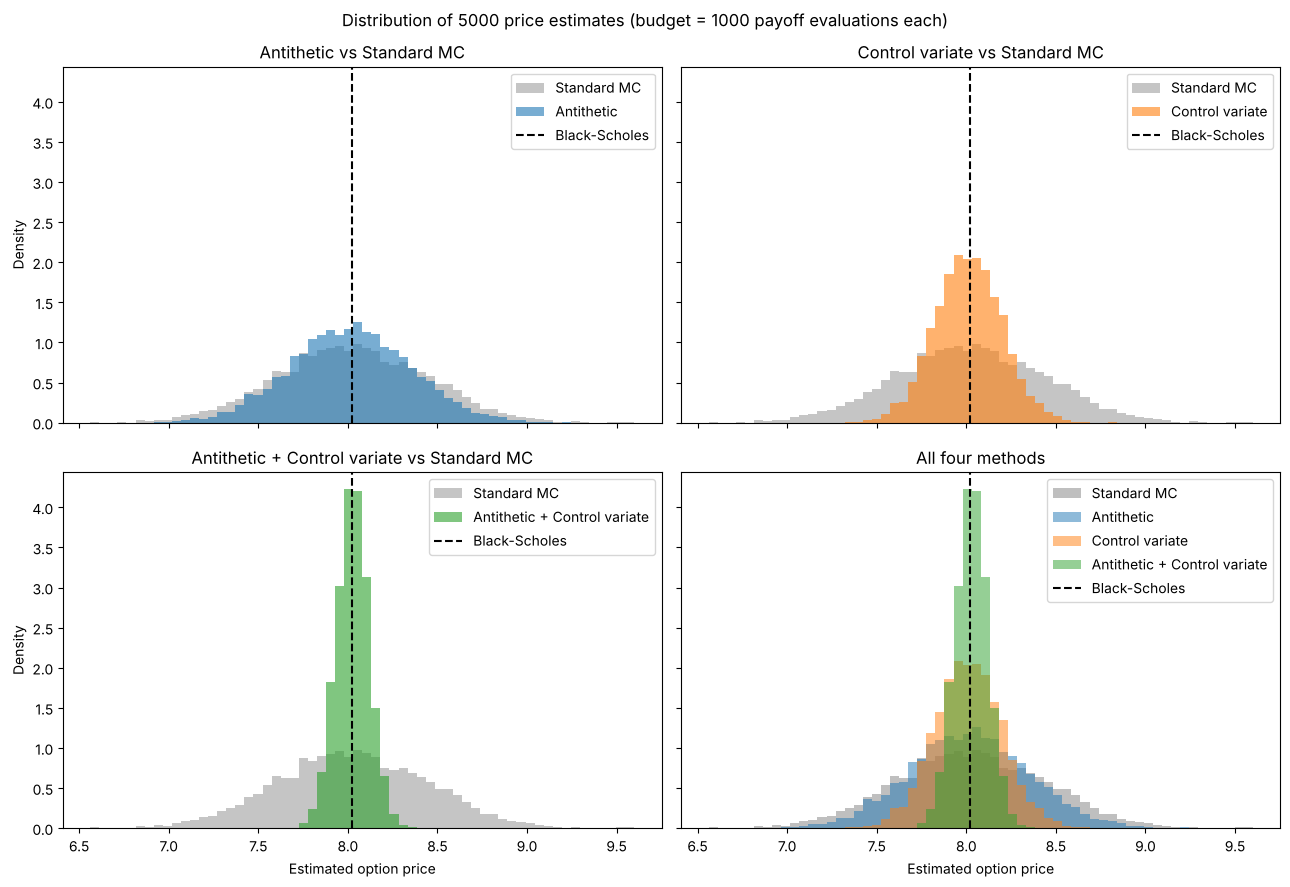

In [14]:
colors = {"Standard MC": "grey", "Antithetic": "tab:blue",
          "Control variate": "tab:orange", "Antithetic + Control variate": "tab:green"}

everything = np.concatenate(list(all_prices.values()))
bins = np.linspace(everything.min(), everything.max(), 61)

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True)

# Panels 1-3: each improved method against Standard MC
for ax, name in zip(axes.ravel()[:3], names[1:]):
    ax.hist(all_prices["Standard MC"], bins=bins, density=True, alpha=0.45,
            color=colors["Standard MC"], label="Standard MC")
    ax.hist(all_prices[name], bins=bins, density=True, alpha=0.6,
            color=colors[name], label=name)
    ax.axvline(black_scholes_price, color="k", linestyle="--", label="Black-Scholes")
    ax.set_title(f"{name} vs Standard MC")
    ax.legend()

# Panel 4: all four together
ax = axes.ravel()[3]
for name in names:
    ax.hist(all_prices[name], bins=bins, density=True, alpha=0.5,
            color=colors[name], label=name)
ax.axvline(black_scholes_price, color="k", linestyle="--", label="Black-Scholes")
ax.set_title("All four methods")
ax.legend()

for ax in axes[1]:
    ax.set_xlabel("Estimated option price")
for ax in axes[:, 0]:
    ax.set_ylabel("Density")

fig.suptitle(f"Distribution of {R} price estimates (budget = {M} payoff evaluations each)")
plt.tight_layout()
plt.show()

## 11. What happens with a bigger budget?

Theory says the typical error of Monte Carlo shrinks like $1/\sqrt{\text{budget}}$: to cut the error in half you need **four times** as many simulations. On a log-log plot this is a straight line with slope $-0.5$. The variance reduction techniques should push the curve **down** (smaller error for the same budget) without changing its slope.

In [15]:
budgets = [100, 250, 500, 1000, 2500, 5000, 10000]
R_conv = 500    # experiments per budget

rmse = {name: [] for name in names}

for n in budgets:
    errors = {name: [] for name in names}
    for i in range(R_conv):
        results = simulate_all(n)
        for name in names:
            errors[name].append(results[name][0] - black_scholes_price)
    for name in names:
        rmse[name].append(np.sqrt(np.mean(np.array(errors[name]) ** 2)))

Standard MC                    slope = -0.52
Antithetic                     slope = -0.50
Control variate                slope = -0.50
Antithetic + Control variate   slope = -0.51


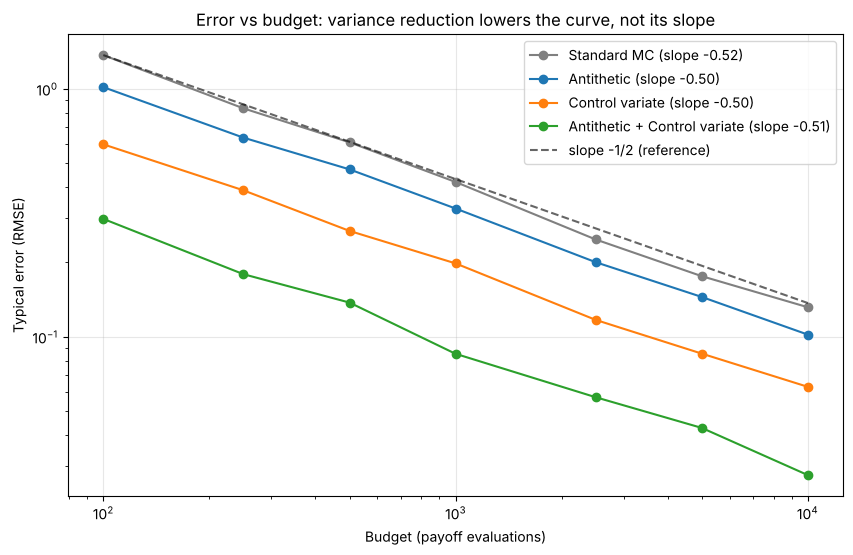

In [16]:
plt.figure(figsize=(10, 6))

for name in names:
    slope = np.polyfit(np.log(budgets), np.log(rmse[name]), 1)[0]
    print(f"{name:30s} slope = {slope:.2f}")
    plt.loglog(budgets, rmse[name], marker="o", color=colors[name],
               label=f"{name} (slope {slope:.2f})")

# Reference line with slope -1/2, starting at the Standard MC error for the smallest budget
reference = rmse["Standard MC"][0] * (np.array(budgets) / budgets[0]) ** -0.5
plt.loglog(budgets, reference, "k--", alpha=0.6, label="slope -1/2 (reference)")

plt.xlabel("Budget (payoff evaluations)")
plt.ylabel("Typical error (RMSE)")
plt.title("Error vs budget: variance reduction lowers the curve, not its slope")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 12. Conclusions

- **Standard Monte Carlo** works, but its error is large for a small budget. Always report it with an error bar: a single price without one means little.
- **Antithetic variates** cut the variance by roughly a third at no extra cost: the mirror image of each random number is free.
- The **control variate** is stronger here (variance cut by about 80%), because the call payoff is strongly linked to the stock price, whose true average we know.
- **Using both together** gives the best result: the variance is roughly 20 times smaller than Standard MC for the same budget. The histograms show it directly: the combined method is the narrowest.
- All methods converge at the same rate, $1/\sqrt{\text{budget}}$ (slope $\approx -0.5$ on a log-log plot). The variance reduction techniques do not change the rate; they reduce the error by a constant factor, which shifts the whole curve down.
- The error bars are trustworthy: 95% confidence intervals contain the true price close to 95% of the time. The combined method is slightly optimistic with a small budget (a bit below 95%).

**Limits of this study.** The option is a simple European call with constant volatility, for which an exact price exists. The real value of Monte Carlo appears for options without a closed formula (for example, options that depend on the whole price path), where these variance-reduction ideas matter even more.

**Possible next steps.** Compare computing *time* instead of payoff evaluations; try other control variates; study quasi-Monte Carlo sequences.